# The Discrete Fourier Transform

In [1]:
%run ../setup.ipynb

In this section, we will formally introduce the Discrete Fourier Transform (DFT).
The DFT is the *digital* version of the Fourier transform, which was originally developed by [Joseph Fourier](https://en.wikipedia.org/wiki/Joseph_Fourier) in the early 19th century as a way to model heat flow with differential equations {cite}`fourier1822theorie`.
The Fourier transform proved to be useful for many different applications, especially in audio and signal processing.

Many texts introduce the DFT by first starting with the continuous Fourier transform (using integral calculus), and then show the DFT as a discrete-time approximation of the continuous Fourier transform.
We'll take a different approach here, motivating the DFT from first principles entirely in the discrete time domain.

```{margin} Aside: the Fast Fourier Transform

If you have previously come across the term *Fast Fourier Transform* (FFT), you might be wondering how the DFT relates to the FFT.

We'll cover the FFT later in {ref}`fft`, but the key take-away is that the FFT is an *algorithm* for efficiently computing the *DFT*.  It is not a separate transformation.
```

## Dealing with phase

Recall that in the previous section, when we compare a sinusoid $\blue{x[n]}$ to a collection of reference signals

```{math}
\red{y_m[n] = \cos\left(2\pi \cdot \frac{m}{N} \cdot n \right)},
```

the resulting similarity score $\purple{S(x, y_m)}$ depends on the phase of the signal, and whether or not the frequency of $\blue{x}$ is an analysis frequency.

In the worst case, if

```{math}
\blue{x[n] = \sin\left(2\pi \cdot \frac{m}{N}\cdot n \right) = 
 \cos\left(2\pi \cdot \frac{m}{N}\cdot n - \frac{\pi}{2} \right),}
```

then the similarity score will be 0 even if the frequency matches one of our reference signals.
This representation therefore cannot distinguish an out-of-phase sinusoid from a null signal $x[n] = 0$.

### Comparing to multiple references

In the specific case above, we could try to resolve the problem by changing the reference signals $\red{y}$ to use $\sin$ instead of $\cos$.
This will fix the problem if $\blue{x}$ is a $\sin$ wave, but then it will fail in exactly the same way if $\blue{x}$ is a $\cos$ wave.

*But what if we try both?*

Let's see what happens if we take $\blue{x}$ as a sinusoid at an analysis frequency with arbitrary phase, and compare it to two reference signals at the same frequency: one is $\cos$ and one is $\sin$.

In the following example, we'll continue with the settings from the previous section: $f_s = 20$ ``[samples / sec]``, $N=40$ ``[samples]``, and $\red{m=3}$ (equivalently, $f_0 = 1.5$ ``[cycles/sec]``).
This gives an input signal

```{math}
:label: analysis-signal

\blue{x[n] = \cos\left(2\pi \cdot \frac{m}{N} \cdot n + \phi \right)}
```
where $\phi$ is allowed to vary.

We'll compare to reference signals

```{math}

\red{\cos\left(2\pi \cdot \frac{m}{N} \cdot n\right)},
\quad\quad\text{and}\quad\quad
\green{\sin\left(2\pi \cdot \frac{m}{N} \cdot n\right)}
```

<Figure size 576x432 with 6 Axes>

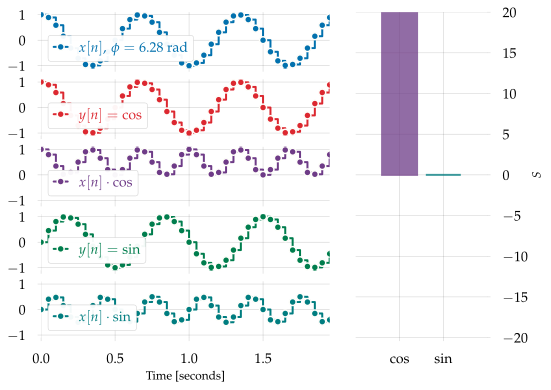

In [4]:
from matplotlib import gridspec

fs = 20
N = 40
t = np.arange(N) / fs
f0 = 1.5
x = np.cos(2 * np.pi * f0 * t)

# Time sample positions
y1 = np.cos(2 * np.pi * f0 * t)

y2 = np.sin(2 * np.pi * f0 * t)

# filter coefficients
xy1 = x * y1
xy2 = x * y2

pxy1sum = np.cumsum(xy1)
pxy2sum = np.cumsum(xy2)

# Set up the plot skeleton
fig = plt.figure(figsize=(8, 6))

legs = []

gs = gridspec.GridSpec(5, 3)

ax1 = plt.subplot(gs[0, 0:2])
# This is the input data
p_x = ax1.step(t, x, label=r'$x[n],\, \phi=0$', where='post', marker='o', zorder=2)[0]

legs.append(ax1.legend(ncol=2, loc='lower left', labelcolor='markerfacecolor'))
ax1.label_outer()

ax2 = plt.subplot(gs[1, 0:2], sharex=ax1, sharey=ax1)

p_y1 = ax2.step(t, y1, label=r'$y[n]=\cos$', where='post', marker='o', color='C1', zorder=2)[0]

ax2.legend(ncol=2, loc='lower left', labelcolor='markerfacecolor')
ax2.label_outer()


ax3 = plt.subplot(gs[2, 0:2], sharex=ax1, sharey=ax1)

p_xy1 = ax3.step(t, xy1, where='post', marker='o', label=r'$x[n] \cdot \cos$',
                    color='C4', zorder=1)[0]

ax3.legend(loc='lower left', labelcolor='markerfacecolor')
ax3.label_outer()

ax5 = plt.subplot(gs[3, 0:2], sharex=ax1, sharey=ax1)
p_y2 = ax5.step(t, y2, label=r'$y[n]=\sin$', where='post', marker='o', color='C5',
                       zorder=2)[0]

ax5.legend(ncol=2, loc='lower left', labelcolor='markerfacecolor')
ax5.label_outer()

ax6 = plt.subplot(gs[4, 0:2], sharex=ax1, sharey=ax1)

p_xy2 = ax6.step(t, xy1, where='post', marker='o', label=r'$x[n] \cdot \sin$',
                   color='C7', zorder=1)[0]
ax6.legend(loc='lower left', labelcolor='markerfacecolor')

ax6.set_xlabel('Time [seconds]')
ax6.set_ylim([-1.1, 1.1])

ax4 = plt.subplot(gs[:, 2])
p_S = ax4.bar(np.arange(2), [0, 0], alpha=0.75, linewidth=2)
p_S[0].set(color='C4', edgecolor='C4')
p_S[1].set(color='C7', edgecolor='C7')
ax4.xaxis.set(ticks=[0, 1], ticklabels=['$\cos$', '$\sin$'])
ax4.yaxis.tick_right()
ax4.set(ylabel='$S$')
ax4.yaxis.set_label_position('right')
ax4.set_ylim([-N//2, N//2])
ax4.set_xlim([-1, 2])

##--
## Animation code
# Animation frame rate
frame_rate = 24
anim_speed = 4

n_frames = int(30 * frame_rate / anim_speed)

phi = np.linspace(0, 2 * np.pi, num=n_frames)

def init():
    return tuple([p_x, p_xy1, p_xy2] + legs + list(p_S))
        
def animate(n):
    x = np.cos(2 * np.pi * f0 * t + phi[n])
    p_x.set_data(t, x)
    p_xy1.set_data(t, x * y1)
    p_xy2.set_data(t, x * y2)
    score = [x.dot(y1), x.dot(y2)]
    for s, b in zip(score, p_S):
        b.set_height(s)

    p_x.set_label('$x[n],\,\\phi={:.02f}$ rad'.format(phi[n]))
    legs[0].texts[0].set_text(p_x.get_label())
    return tuple([p_x, p_xy1, p_xy2] + legs + list(p_S))

animation = FuncAnimation(fig, animate, init_func=init,
                               frames=np.arange(n_frames),
                               interval=1000./frame_rate, blit=True,
                               repeat_delay=1000);

glue('sincos-similarity', animation, display=False)

In [5]:
animation

Once 
 
 Loop 
 
 Reflect

```{glue:figure} sincos-similarity
---
name: sincos-similarity
---

A sinusoid $\blue{x}$ at an analysis frequency but with varying phase $\phi$ (top plot) is compared to two reference signals: $\red{\cos}$ (second plot) and $\green{\sin}$ (fourth plot), producing element-wise products (third and fifth plots).
On the right, the resulting similarity scores for both reference signals are shown as $\phi$ varies.
```

{numref}`sincos-similarity` illustrates what happens to similarity scores as we vary the phase $\phi$ of $x$ while comparing to both cosine and sine waves.
Note that although either score can be positive, negative, or 0, **they cannot both be 0 simultaneously**.

Recall from {eq}`phase-similarity` that the similarity score for $x$ and the reference signal $\cos(2\pi \cdot n\cdot m/N)$ depends on $\phi$: $S = \frac{N}{2} \cdot \cos\phi$ (if $m\neq N/2$).
By similar reasoning, we can calculate the similarity between $x$ and the $\sin$ reference signal:

```{div} full-width
\begin{align*}
S 
&= \sum_{n=0}^{N-1} 
\blue{\cos\left(2\pi \cdot \frac{m}{N} \cdot n + \phi \right)} \cdot  \green{\sin\left(2\pi \cdot \frac{m}{N} \cdot n \right)}\\
&= \sum_{n=0}^{N-1} 
\frac{1}{2}  \cdot \blue{\sin\left(2\pi \cdot \frac{m+m}{N} \cdot n + \phi\right)} - 
\frac{1}{2}  \cdot \green{\sin\left(2\pi \cdot \frac{m-m}{N} \cdot n + \phi \right)} & \text{by product-to-sum rule}\\
&= \sum_{n=0}^{N-1} 
\frac{1}{2}  \cdot \blue{\sin\left(2\pi \cdot \frac{2m}{N} \cdot n + \phi \right)} - 
\frac{1}{2}  \cdot \green{\sin\left(\phi\right)} & \text{cancel } m-m=0 \\
&= \left(\frac{1}{2}\sum_{n=0}^{N-1} 
\blue{\sin\left(2\pi \cdot \frac{2m}{N} \cdot n + \phi \right)}\right) -
\frac{N}{2} \cdot \green{\sin\left(\phi\right)}  & \text{pull} -\frac{1}{2}\sin(\phi) \text{ out of sum}\\
\end{align*}
```

If $m \notin \{0, N/2\}$, then the $\blue{\text{first term}}$ of the summation will total to 0 because it completes a whole number of cycles in $N$ samples.
The resulting score in this case is

```{math}
S = -\frac{N}{2}\cdot \green{\sin\left(\phi\right)} \quad\quad\quad \text{if } m \notin \{0, N/2\}.
```

Otherwise, if $m=0$ or $m=N/2$, the first term simplifies to

```{math}
\blue{\sin\left(2\pi \cdot \frac{2m}{N} \cdot n + \phi\right)} 
= \blue{\sin\left(2\pi \cdot \frac{0}{N} \cdot n + \phi\right)}
= \blue{\sin\left(\phi\right)}.
```

Combining this with the derivation above, we get the total similarity score:

```{math}
:label: sin0

S = \frac{N}{2} \cdot \blue{\sin(\phi)} - \frac{N}{2} \cdot \green{\sin(\phi)} = 0 \quad\quad\quad \text{if } m \in \{0, N/2\}.
```

### Combining terms

Stepping back, if we take $m \notin \{0, N/2\}$, pick an arbitrary phase $\phi$, generate a signal $x[n]$ according to Equation {eq}`analysis-signal`, and compare it to cosine and sine waveforms as above, we will observe the following similarity scores:

- $\purple{S(x, \cos) = \frac{N}{2} \cdot \cos(\phi)}$
- $\cyan{S(x, \sin) = -\frac{N}{2} \cdot \sin(\phi)}$.

If we additionally scale $x$ by an amplitude $A$, this scaling factor would carry through all of the summations above:

- $\purple{S(A\cdot x, \cos) = \frac{N}{2} \cdot A \cdot \cos(\phi)}$
- $\cyan{S(A\cdot x, \sin) = -\frac{N}{2} \cdot A \cdot \sin(\phi)}$.

This is starting to look pretty interesting.
However, it would be better if both scores had the same sign.
We can accomplish this by changing which signals we compare to: instead of comparing to $\green{\sin\left(2\pi\cdot\frac{m}{N}\cdot n\right)}$, we'll compare to $\green{-\sin\left(2\pi\cdot\frac{m}{N}\cdot n\right)}$.
Since this is just a multiplication by $-1$, like the amplitude scaling above, we can push it through the similarity calculation and obtain:

- $\purple{S(A\cdot x, \cos) = \frac{N}{2} \cdot A \cdot \cos(\phi)}$
- $\cyan{S(A\cdot x, -\sin) = \frac{N}{2} \cdot A \cdot \sin(\phi)}$.

**Now this is interesting.**

We started with a sinusoid $x$ having amplitude $A$ and phase offset $\phi$.
The resulting scores can be interpreted as horizontal and vertical coordinates of a point with radius $A\cdot N/2$ and angle $\phi$.

<Figure size 576x360 with 4 Axes>

<Figure size 576x360 with 4 Axes>

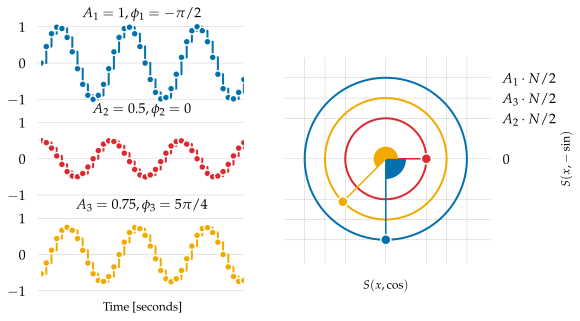

In [20]:
# Set up the plot skeleton
fig = plt.figure(figsize=(8, 5))

gs = gridspec.GridSpec(3, 2)

t = np.arange(N) / fs
f0 = 1.5
x1 = np.sin(2 * np.pi * f0 * t)

ax1 = plt.subplot(gs[0, 0])
ax1.step(t, x1, marker='o', where='post')
ax1.label_outer()
ax1.set_title(r'$A_1=1, \phi_1=-\pi/2$')

x2 = 0.5 * np.cos(2 * np.pi * f0 * t)
ax2 = plt.subplot(gs[1, 0], sharex=ax1, sharey=ax1)
ax2.step(t, x2, marker='o', where='post', color='C1')
ax2.label_outer()
ax2.set_title(r'$A_2=0.5, \phi_2=0$')


x3 = 0.75 * np.cos(2 * np.pi * f0 * t + np.pi * 5 / 4)
ax4 = plt.subplot(gs[2, 0], sharex=ax1, sharey=ax1)
ax4.step(t, x3, marker='o', where='post', color='C2')
ax4.label_outer()
ax4.set(title=r'$A_3=0.75, \phi_3=5\pi/4$')
ax4.set(xticks=[])
ax4.set(xlabel='Time [seconds]')

ax3 = plt.subplot(gs[:, 1:])

ax3.plot([0, 0], [-N/2, 0, ], color='C0', linewidth=1.5, marker='o', markevery=2, markersize=10)
ax3.plot([0.5 * 0.5 * N, 0], [0, 0], color='C1', linewidth=1.5, marker='o', markevery=2, zorder=5, markersize=10)
ax3.plot([0.75 * N/2 * np.cos(5 * np.pi/4), 0], [0.75 * N/2 * np.sin(5 * np.pi/4), 0], color='C2', linewidth=1.5, marker='o', markevery=2, zorder=5, markersize=10)

circ1 = patches.Ellipse((0, 0), N, N, facecolor='none', edgecolor='C0', linewidth=2)
ax3.add_patch(circ1)
w = patches.Wedge((0, 0), N/2 * 0.25, theta2=0, theta1=-np.pi/2 * 180 / np.pi,
                        facecolor='C0')
ax3.add_patch(w)


circ2 = patches.Ellipse((0, 0), 0.5 * N, 0.5 * N, facecolor='none', edgecolor='C1', linewidth=2)
ax3.add_patch(circ2)

circ3 = patches.Ellipse((0, 0), 0.75 * N, 0.75 * N, facecolor='none', edgecolor='C2', linewidth=2)
ax3.add_patch(circ3)
w = patches.Wedge((0, 0), N/2 * 0.15, theta1=0, theta2=5 * np.pi / 4 * 180 / np.pi,
                        facecolor='C2', zorder=10,)
ax3.add_patch(w)
ax3.set(xlim=[-N/2 - 5, N/2+5], ylim=[-N/2 - 5, N/2+5])
ax3.set_aspect('equal')
ax3.set_xlabel(r'$S(x, \cos)$')
ax3.set_ylabel(r'$S(x, -\sin)$')
tp = [-N/2, -3*N/8, -N/4, 0, N/4, 3*N/8, N/2]
tl = ['', '', '', 0,
      r'$A_2 \cdot N / 2$',
      r'$A_3 \cdot N/2$', 
      r'$A_1 \cdot N/2$', 
     ]
ax3.set(xticks=tp, yticks=tp, xticklabels=[], yticklabels=tl)
ax3.yaxis.set_label_position('right')
ax3.yaxis.tick_right();
glue('dft-examples', fig, display=False)

```{glue:figure} dft-examples
---
name: dft-examples
alt: illustration of amplitude and phase encoded as complex numbers
---

*Left*: three different waves of the form $x[n] = A \cdot \cos(2\pi \cdot n \cdot m / N + \phi)$ are compared to $\cos$ and $-\sin$ reference signals with the same frequency.  *Right*: interpreting the similarity scores for each signal as horizontal and vertical coordinates places each one on a circle of radius $A \cdot N/2$ at angle $\phi$.
```

Rather than carry around two coordinates for each frequency comparison, we can combine them into a single complex number.
We will associate the comparison to $\cos$ with the **real** part, and the comparison to $-\sin$ with the **imaginary** part.

(dft)=
## The Discrete Fourier Transform

Finally, we can formally define the discrete Fourier transform (DFT).
The DFT takes as input a signal $x[n]$ of $N$ samples, and produces a sequence $X[m]$ of $N$ complex numbers representing amplitude and phase for each analysis frequency.

````{prf:definition} The discrete Fourier transform (DFT)

For an arbitrary input signal $\blue{x[n]}$ of $\blue{N}$ samples, its discrete Fourier transform is a sequence of $N$ complex numbers $\darkblue{X[m]}$ ($\red{m=0,1,\dots,N-1}$)
defined as follows:

```{math}
:label: dft-rect

\darkblue{X[m]} = \sum_{n=0}^{N-1} \blue{x[n]} \cdot \left(
    \red{\cos\left(2\pi \cdot \frac{m}{N}\cdot n\right)} - 
    \mathrm{j}\cdot\green{\sin\left(2\pi \cdot \frac{m}{N}\cdot n\right)}
\right)
```
or, equivalently using Euler's formula {eq}`euler`,

```{math}
:label: dft-polar

\darkblue{X[m]} = \sum_{n=0}^{N-1} \blue{x[n]} \cdot \purple{\exp\left(-\mathrm{j}\cdot 2\pi \cdot \frac{m}{N} \cdot n\right)}.
```
````

```{margin} DFT notation
The $\darkblue{X[m]}$ (capital) notation for the DFT of $\blue{x}$ is common, but not universal.

Some other notations that you might see in the wild include

- $\hat{x}[m]$, and 
- $\mathcal{F}(x)[m]$.
```

The DFT equation {eq}`dft-rect` can be implemented in code as follows:

(dft-naive)=
```python
import numpy as np

def dft(x):
    '''The Discrete Fourier Transform
    
    Parameters
    ----------
    x : np.ndarray
        The input signal
        
    Returns
    -------
    X : np.ndarray, same shape as x
        The DFT sequence: X[m] corresponds to analysis frequency index m
    '''
    
    # Get the number of samples = number of frequencies
    N = len(x)
    
    # Allocate the output array
    X = np.zeros(N, dtype=complex)
    
    # For each analysis frequency
    for m in range(N):
        # For each sample
        for n in range(N):
            # Compare to cos and -sin at this frequency
            X[m] = X[m] + x[n] * (np.cos(2 * np.pi * m / N * n) 
                                     - 1j * np.sin(2 * np.pi * m / N * n))
    # Return the DFT array
    return X
```

Note that this code will be **extremely slow**, and should not be used for long signals.
Instead, you should probably use a *fast Fourier transform* (FFT) implementation, like the one provided by ``numpy``:

```python
import numpy as np

X = np.fft.fft(x)
```

### Some facts about the DFT

In the coming chapters, we will devote a significant amount of time to understanding everything we can about the DFT.
For the time being, here is a brief list of basic facts that can be derived by a close examination of our process in building up the DFT.

For convenience, we will write $\text{DFT}(x)$ to denote the entire sequence of DFT *components* $\darkblue{X[0], X[1], X[2], \dots, X[N-1]}$.

1. The DFT sequence $\darkblue{X[0], X[1], \dots X[N-1]}$ does not index *time* like the sample array $\blue{x[n]}$ does.  Instead, each $\darkblue{X[m]}$ measures the contribution of a sinusoid at a particular frequency to the **entire signal** $\blue{x}$.

2. The DFT sequence always has the same number of analysis frequencies as the number of samples $\blue{N}$.  The first $N/2$ correspond to positive frequencies, the last $N/2$ correspond to negative frequencies.

3. The $\red{m=0}$ component is always a real number---this follows immediately from {eq}`sin0`.  It is known as the *direct current* (DC) component, and always equals the sum of the sample values.

4. For each $\darkblue{X[m]}$, the magnitude $|\darkblue{X[m]}|$ (``np.abs(X[m])``) corresponds to the amplitude of a sinusoid at frequency $f_s \cdot \red{m} / \blue{N}$ present in the signal. Similarly, its angle in the complex plan, $\angle \darkblue{X[m]}$ (``np.angle(X[m])``), corresponds to the **phase** of the sinusoid.

5. The sequence of values $|\darkblue{X[m]}|$ is known as the **magnitude spectrum** of $\blue{x}$.

6. The magnitude $|\darkblue{X[m]}|$ is not the same as the real part $\red{\mathsf{Re}X[m]}$.  Remember that for a complex number $z$,
```{math}
|z| = \sqrt{\red{\left(\mathsf{Re}z\right)^2} + \purple{\left(\mathsf{Im}z\right)^2}}
```
Both the real and imaginary parts of the number contribute to both magnitude and phase.

## Summary

Developing the DFT takes a lot of work.  So does understanding it completely.
**Don't panic if this section was difficult to get through.**

To finish off this chapter, the next section will show several examples signals and their corresponding DFTs.